In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, ConfusionMatrixDisplay

import shap
from lime.lime_tabular import LimeTabularExplainer

RS = 42
print('shap', shap.__version__)

shap 0.54.1


In [2]:
UCI = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
try:
    raw = pd.read_csv('../data/raw/german.data', sep=' ', header=None)
except FileNotFoundError:
    raw = pd.read_csv(UCI, sep=' ', header=None)

code = lambda col, m: raw[col].map(m)
df = pd.DataFrame({
    'account': code(0, {'A11': -1, 'A14': 0, 'A12': 1, 'A13': 2}),
    'duration': raw[1],
    'credit_history': code(2, {'A30': 0, 'A31': 1, 'A32': 2, 'A33': 3, 'A34': 4}),
    'amount': raw[4],
    'savings': code(5, {'A65': 0, 'A61': 1, 'A62': 2, 'A63': 3, 'A64': 4}),
    'employment': code(6, {'A71': 0, 'A72': 1, 'A73': 2, 'A74': 3, 'A75': 4}),
    'installment_rate': raw[7],
    'guarantors': (raw[9] == 'A103').astype(int),
    'residence': raw[10],
    'age': raw[12],
    'credits_number': raw[15],
    'job': code(16, {'A171': 0, 'A172': 1, 'A173': 2, 'A174': 3}),
    'maintenance_people': raw[17],
    'telephone': (raw[18] == 'A192').astype(int),
    'foreign': (raw[19] == 'A201').astype(int),
    'real_estate': (raw[11] == 'A121').astype(int),
    'life_insurance': (raw[11] == 'A122').astype(int),
    'car': (raw[11] == 'A123').astype(int),
    'housing_rent': (raw[14] == 'A151').astype(int),
    'target': (raw[20] == 1).astype(int),
})
assert df.isna().sum().sum() == 0

class_names = ['bad (отказ)', 'good (надёжный)']
print('Размер данных:', df.shape)
print('Классы:', df['target'].value_counts().sort_index().rename(dict(enumerate(class_names))).to_dict())
df.head()

Размер данных: (1000, 20)
Классы: {'bad (отказ)': 300, 'good (надёжный)': 700}


,account,duration,credit_history,amount,savings,employment,installment_rate,guarantors,residence,age,credits_number,job,maintenance_people,telephone,foreign,real_estate,life_insurance,car,housing_rent,target
0,-1,6,4,1169,0,4,4,0,4,67,2,2,1,1,1,1,0,0,0,1
1,1,48,2,5951,1,2,2,0,2,22,1,2,1,0,1,1,0,0,0,0
2,0,12,4,2096,1,3,2,0,3,49,1,1,2,0,1,1,0,0,0,1
3,-1,42,2,7882,1,3,2,1,4,45,1,2,2,0,1,0,1,0,0,1
4,-1,24,3,4870,1,2,3,0,4,53,2,2,2,0,1,0,0,0,0,0


In [3]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)
print('Обучающая выборка:', X_train.shape, ' доля good:', y_train.mean().round(3))
print('Тестовая выборка: ', X_test.shape, ' доля good:', y_test.mean().round(3))

Обучающая выборка: (800, 19)  доля good: 0.7
Тестовая выборка:  (200, 19)  доля good: 0.7


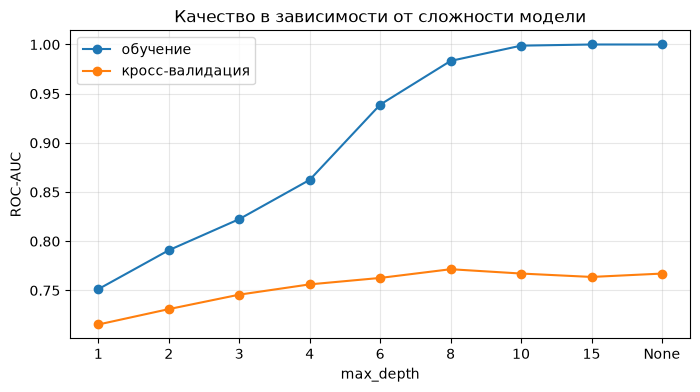

,max_depth,ROC-AUC train,ROC-AUC CV
0,1,0.751,0.715
1,2,0.791,0.731
2,3,0.822,0.746
3,4,0.862,0.756
4,6,0.939,0.763
5,8,0.983,0.772
6,10,0.999,0.767
7,15,1.000,0.764
8,None,1.000,0.767


In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
rows = []
for depth in [1, 2, 3, 4, 6, 8, 10, 15, None]:
    m = RandomForestClassifier(n_estimators=200, max_depth=depth, random_state=RS, n_jobs=-1)
    m.fit(X_train, y_train)
    rows.append({'max_depth': str(depth),
                 'ROC-AUC train': roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
                 'ROC-AUC CV': cross_val_score(m, X_train, y_train, cv=cv, scoring='roc_auc').mean()})
complexity = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
plt.plot(complexity['max_depth'], complexity['ROC-AUC train'], marker='o', label='обучение')
plt.plot(complexity['max_depth'], complexity['ROC-AUC CV'], marker='o', label='кросс-валидация')
plt.xlabel('max_depth'); plt.ylabel('ROC-AUC'); plt.title('Качество в зависимости от сложности модели'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
complexity.round(3)

In [5]:
best_depth = complexity.loc[complexity['ROC-AUC CV'].idxmax(), 'max_depth']
best_depth = None if best_depth == 'None' else int(best_depth)
print('Выбранная глубина:', best_depth)

Выбранная глубина: 8


Accuracy train = 0.884
Accuracy test  = 0.795
ROC-AUC test   = 0.823
Базовый уровень (всегда «good»): 0.700

                 precision    recall  f1-score   support

    bad (отказ)       0.79      0.43      0.56        60
good (надёжный)       0.80      0.95      0.87       140

       accuracy                           0.80       200
      macro avg       0.79      0.69      0.71       200
   weighted avg       0.79      0.80      0.77       200



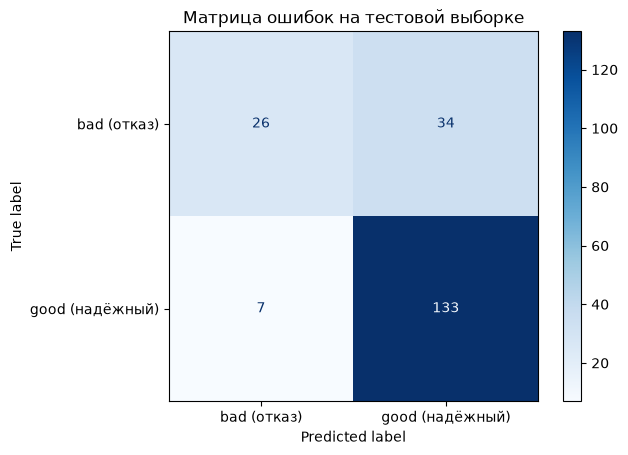

In [6]:
model = RandomForestClassifier(n_estimators=200, max_depth=best_depth, min_samples_leaf=2, random_state=RS, n_jobs=-1)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
proba_test = model.predict_proba(X_test)[:, 1]
print(f'Accuracy train = {accuracy_score(y_train, model.predict(X_train)):.3f}')
print(f'Accuracy test  = {accuracy_score(y_test, y_pred):.3f}')
print(f'ROC-AUC test   = {roc_auc_score(y_test, proba_test):.3f}')
print(f'Базовый уровень (всегда «good»): {y_test.mean():.3f}\n')
print(classification_report(y_test, y_pred, target_names=class_names))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, cmap='Blues')
plt.title('Матрица ошибок на тестовой выборке'); plt.show()

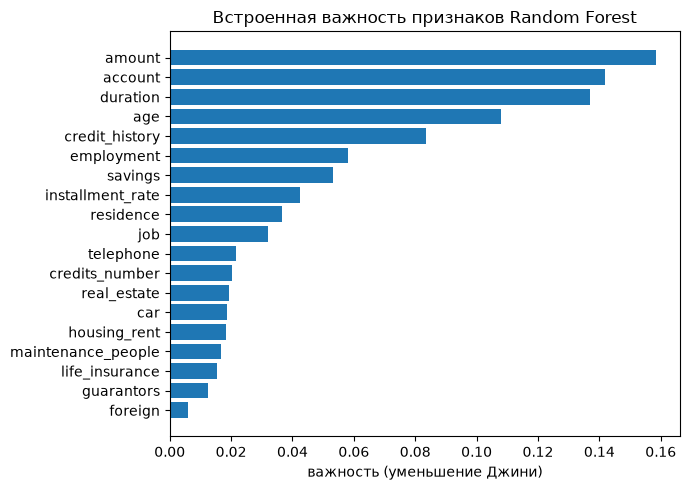

,Feature,Importance
0,amount,0.1583
1,account,0.1419
2,duration,0.1369
3,age,0.1080
4,credit_history,0.0836
5,employment,0.0580
6,savings,0.0533
7,installment_rate,0.0425
8,residence,0.0367
9,job,0.0321


In [7]:
importance = pd.DataFrame({'Feature': X.columns, 'Importance': model.feature_importances_}) \
    .sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(7, 5))
plt.barh(importance['Feature'][::-1], importance['Importance'][::-1])
plt.xlabel('важность (уменьшение Джини)'); plt.title('Встроенная важность признаков Random Forest'); plt.tight_layout(); plt.show()
importance.head(10).round(4)

In [8]:
background = shap.sample(X_train, 100, random_state=RS)   # фон — 100 случайных объектов train (быстро и достаточно точно)
explainer = shap.Explainer(model, background)
shap_values = explainer(X_test)
print('Размер массива SHAP-значений:', shap_values.values.shape)

class_1_values = shap_values[:, :, 1]
print('Базовое значение E[f(x)] для класса 1:', round(float(class_1_values.base_values[0]), 3),
      '(средняя вероятность «good» на фоновой выборке)')

Размер массива SHAP-значений: (200, 19, 2)
Базовое значение E[f(x)] для класса 1: 0.702 (средняя вероятность «good» на фоновой выборке)


**6.1. Bar-график** — признаки по среднему модулю SHAP-значения (глобальная важность).

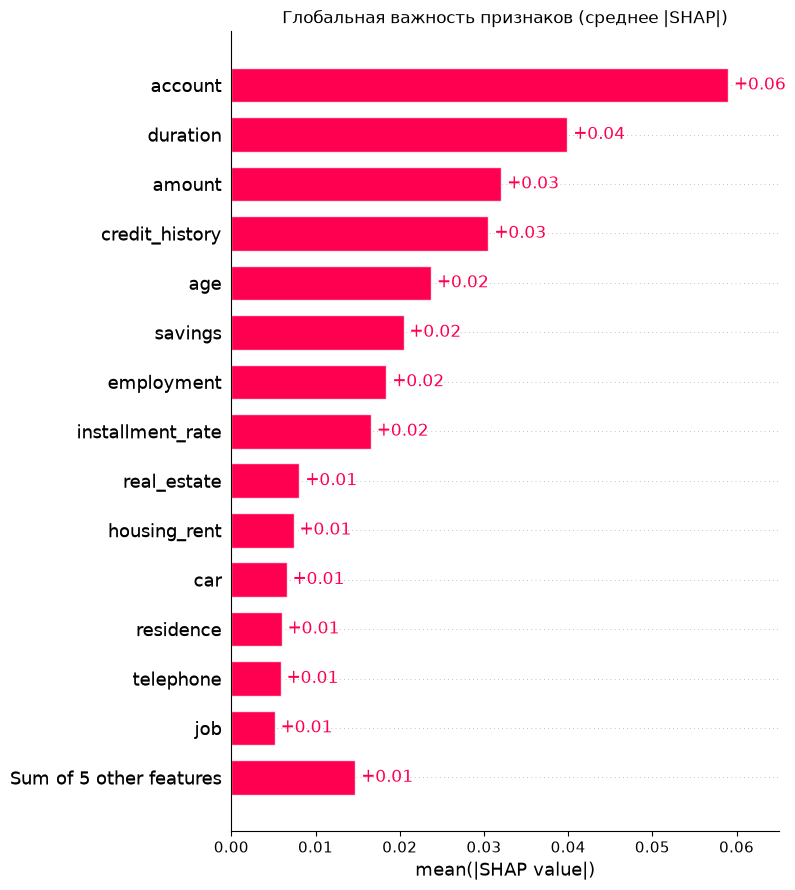

In [9]:
shap.plots.bar(class_1_values, max_display=15, show=False)
plt.title('Глобальная важность признаков (среднее |SHAP|)'); plt.tight_layout(); plt.show()

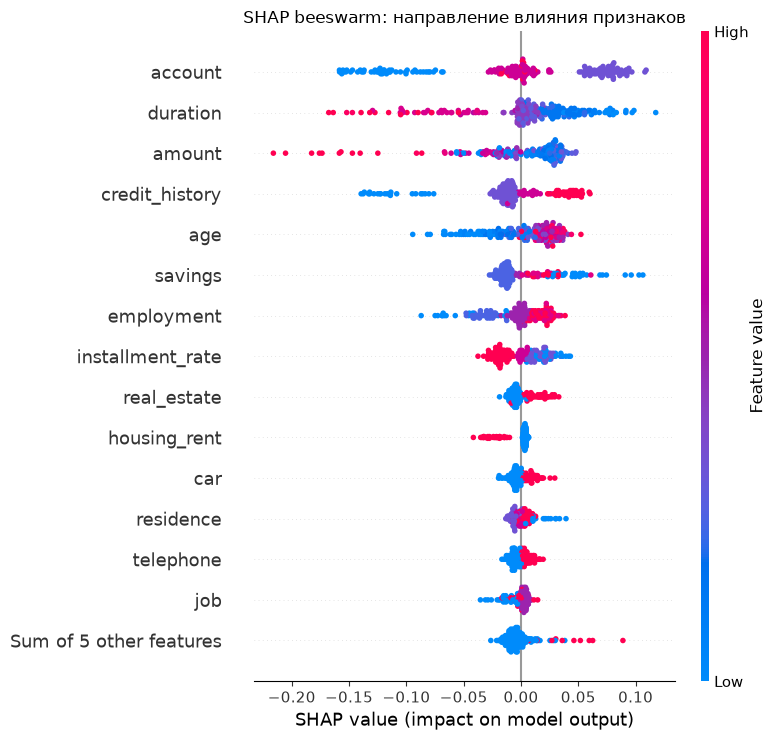

In [10]:
shap.plots.beeswarm(class_1_values, max_display=15, show=False)
plt.title('SHAP beeswarm: направление влияния признаков'); plt.tight_layout(); plt.show()

**6.3. Пять наиболее значимых признаков**

In [11]:
mean_abs_shap = np.abs(class_1_values.values).mean(axis=0)
direction = [np.corrcoef(X_test[f], class_1_values.values[:, i])[0, 1] for i, f in enumerate(X.columns)]
top_features = pd.DataFrame({'Feature': X.columns, 'MeanAbsSHAP': mean_abs_shap, 'direction': direction}) \
    .sort_values('MeanAbsSHAP', ascending=False).reset_index(drop=True)
top_features['влияние'] = np.where(top_features['direction'] > 0, 'больше → надёжнее', 'больше → рискованнее')
top_features.head(5).round(4)

,Feature,MeanAbsSHAP,direction,влияние
0,account,0.0590,0.4271,больше → надёжнее
1,duration,0.0399,-0.9306,больше → рискованнее
2,amount,0.0321,-0.7760,больше → рискованнее
3,credit_history,0.0305,0.8942,больше → надёжнее
4,age,0.0237,0.7206,больше → надёжнее


**Сравнение встроенной важности и SHAP** (ранги признаков, 1 — самый важный):

In [12]:
ranks = pd.DataFrame({
    'ранг RF importance': importance.reset_index().set_index('Feature')['index'] + 1,
    'ранг SHAP': top_features.reset_index().set_index('Feature')['index'] + 1,
}).sort_values('ранг SHAP')
ranks.head(10)

,ранг RF importance,ранг SHAP
Feature,,
account,2,1
duration,3,2
amount,1,3
credit_history,5,4
age,4,5
savings,7,6
employment,6,7
installment_rate,8,8
real_estate,13,9


In [13]:
index = int(np.argmin(proba_test))           
sample = X_test.iloc[[index]]
prediction = int(model.predict(sample)[0])
probability = model.predict_proba(sample)[0]

print('Номер клиента в исходной таблице:', sample.index[0])
print('Предсказанный класс:', class_names[prediction], ' истинный класс:', class_names[y_test.iloc[index]])
print('Вероятности классов [bad, good]:', probability.round(3))
sample.T.rename(columns={sample.index[0]: 'значение'})

Номер клиента в исходной таблице: 998
Предсказанный класс: bad (отказ)  истинный класс: bad (отказ)
Вероятности классов [bad, good]: [0.679 0.321]


,значение
account,-1
duration,45
credit_history,2
amount,1845
savings,1
employment,2
installment_rate,4
guarantors,0
residence,4
age,23


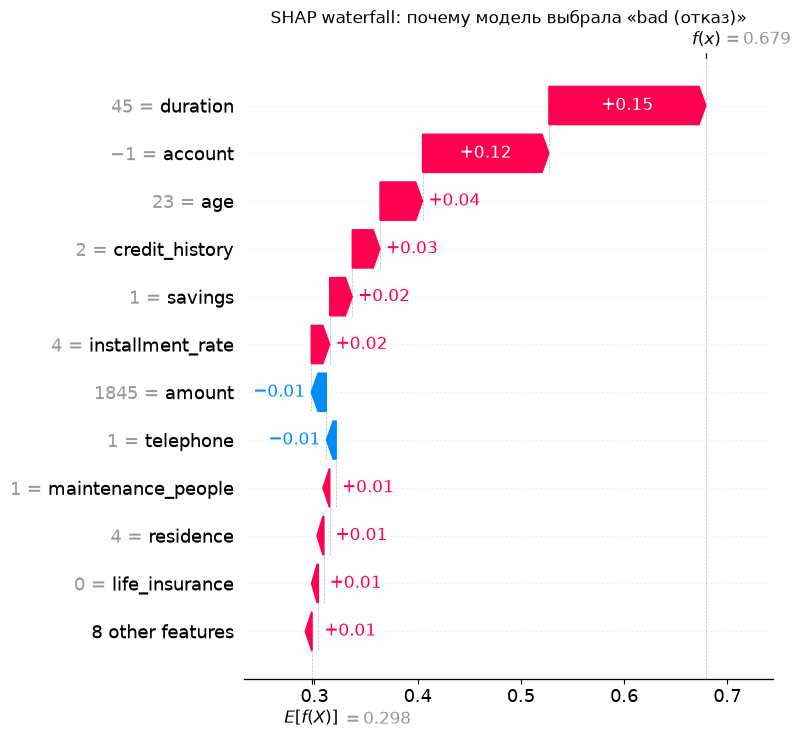

In [14]:
shap.plots.waterfall(shap_values[index, :, prediction], max_display=12, show=False)
plt.title(f'SHAP waterfall: почему модель выбрала «{class_names[prediction]}»'); plt.tight_layout(); plt.show()

In [15]:
sv = shap_values[index, :, prediction]
print(f'базовое значение      = {sv.base_values:.4f}')
print(f'сумма вкладов φ       = {sv.values.sum():+.4f}')
print(f'базовое + сумма       = {sv.base_values + sv.values.sum():.4f}')
print(f'вероятность от модели = {probability[prediction]:.4f}')
assert np.isclose(sv.base_values + sv.values.sum(), probability[prediction], atol=1e-6)

shap_local = pd.Series(sv.values, index=X.columns, name='SHAP').sort_values(key=np.abs, ascending=False)
shap_local.head(10).round(4)

базовое значение      = 0.2977
сумма вкладов φ       = +0.3815
базовое + сумма       = 0.6792
вероятность от модели = 0.6792


duration              0.1521
account               0.1224
age                   0.0412
credit_history        0.0269
savings               0.0218
installment_rate      0.0179
amount               -0.0147
telephone            -0.0095
maintenance_people    0.0063
residence             0.0056
Name: SHAP, dtype: float64

Accuracy дерева глубины 3 на test: 0.750

account = -1 <= -0.50
credit_history = 2 <= 3.50
guarantors = 0 <= 0.50
лист → класс «bad (отказ)»


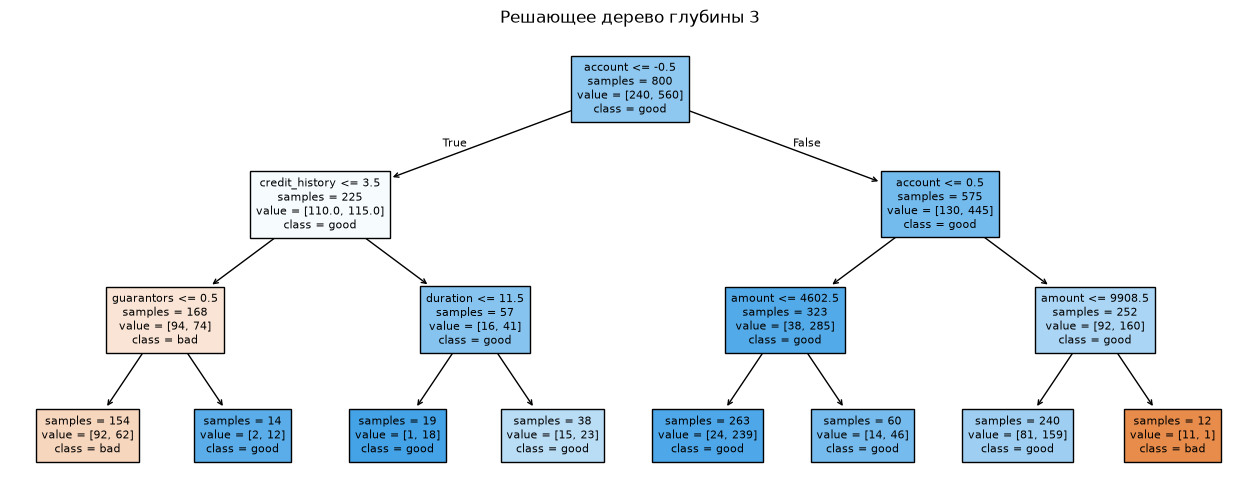

In [16]:
tree = DecisionTreeClassifier(max_depth=3, random_state=RS).fit(X_train, y_train)
print(f'Accuracy дерева глубины 3 на test: {tree.score(X_test, y_test):.3f}\n')

node_ids = tree.decision_path(sample).indices
t = tree.tree_
for node in node_ids:
    if t.children_left[node] == -1:
        print(f'лист → класс «{class_names[int(np.argmax(t.value[node]))]}»')
    else:
        f, thr = X.columns[t.feature[node]], t.threshold[node]
        val = sample.iloc[0][f]
        print(f'{f} = {val} {"<=" if val <= thr else ">"} {thr:.2f}')

plt.figure(figsize=(16, 6))
plot_tree(tree, feature_names=X.columns, class_names=['bad', 'good'], filled=True, fontsize=8, impurity=False)
plt.title('Решающее дерево глубины 3'); plt.show()

In [17]:
categorical = [i for i, c in enumerate(X.columns) if X[c].nunique() <= 5]
print('Категориальные для LIME:', [X.columns[i] for i in categorical])

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X.columns.tolist(),
    class_names=class_names,
    categorical_features=categorical,
    mode='classification',
    random_state=RS,
)
instance = X_test.iloc[index].values
predict_fn = lambda arr: model.predict_proba(pd.DataFrame(arr, columns=X.columns))

lime_exp = lime_explainer.explain_instance(instance, predict_fn, num_features=10, labels=(prediction,))
for cond, w in lime_exp.as_list(label=prediction):
    print(f'{cond:40s} {w:+.4f}')
print('\nR² локальной линейной модели (насколько хорошо она приближает лес рядом с объектом):', round(lime_exp.score, 3))

Категориальные для LIME: ['account', 'credit_history', 'savings', 'employment', 'installment_rate', 'guarantors', 'residence', 'credits_number', 'job', 'maintenance_people', 'telephone', 'foreign', 'real_estate', 'life_insurance', 'car', 'housing_rent']
account=-1                               +0.1434
duration > 24.00                         +0.1226
age <= 27.00                             +0.0504
1329.00 < amount <= 2246.50              -0.0420
savings=1                                +0.0356
foreign=1                                +0.0273
installment_rate=4                       +0.0248
guarantors=0                             +0.0230
housing_rent=0                           -0.0225
credit_history=2                         +0.0224

R² локальной линейной модели (насколько хорошо она приближает лес рядом с объектом): 0.488


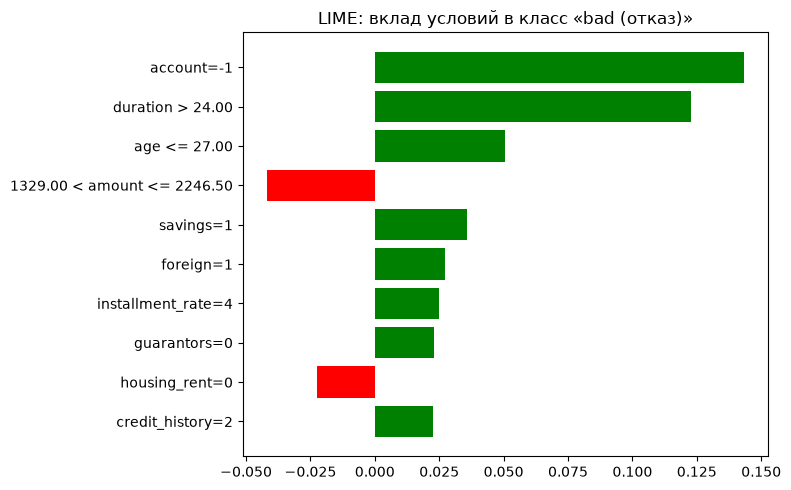

In [18]:
fig = lime_exp.as_pyplot_figure(label=prediction)
fig.set_size_inches(8, 5)
plt.title(f'LIME: вклад условий в класс «{class_names[prediction]}»'); plt.tight_layout(); plt.show()

In [19]:
def lime_weights(seed):
    e = LimeTabularExplainer(X_train.values, feature_names=X.columns.tolist(), class_names=class_names,
                             categorical_features=categorical, mode='classification', random_state=seed)
    exp = e.explain_instance(instance, predict_fn, num_features=len(X.columns), labels=(prediction,))
    return pd.Series({X.columns[i]: w for i, w in exp.as_map()[prediction]})

stab = pd.DataFrame({f'seed={s}': lime_weights(s) for s in [0, 1, 2, 3, 4]})
stab['среднее'] = stab.mean(axis=1)
stab['разброс (std)'] = stab.iloc[:, :5].std(axis=1)
stab.reindex(stab['среднее'].abs().sort_values(ascending=False).index).head(10).round(4)

,seed=0,seed=1,seed=2,seed=3,seed=4,среднее,разброс (std)
account,0.1452,0.1426,0.1408,0.1411,0.1496,0.1439,0.0036
duration,0.1195,0.1188,0.1176,0.1234,0.1154,0.1189,0.0029
age,0.0529,0.0479,0.0512,0.0536,0.0544,0.0520,0.0026
amount,-0.0386,-0.0412,-0.0335,-0.0450,-0.0431,-0.0403,0.0044
savings,0.0370,0.0414,0.0329,0.0394,0.0350,0.0372,0.0034
guarantors,0.0390,0.0282,0.0280,0.0306,0.0296,0.0311,0.0046
installment_rate,0.0289,0.0294,0.0294,0.0269,0.0346,0.0298,0.0029
housing_rent,-0.0233,-0.0296,-0.0296,-0.0282,-0.0227,-0.0267,0.0034
credit_history,0.0196,0.0165,0.0202,0.0224,0.0218,0.0201,0.0023
real_estate,0.0172,0.0194,0.0212,0.0208,0.0209,0.0199,0.0017


In [20]:
lime_local = stab['seed=0'] if RS == 0 else lime_weights(RS)   # веса LIME по всем 19 признакам
cmp = pd.DataFrame({'SHAP': shap_local, 'LIME': lime_local})
cmp['ранг SHAP'] = cmp['SHAP'].abs().rank(ascending=False).astype(int)
cmp['ранг LIME'] = cmp['LIME'].abs().rank(ascending=False).astype(int)
cmp['знак совпал'] = np.sign(cmp['SHAP']) == np.sign(cmp['LIME'])
cmp = cmp.sort_values('ранг SHAP')

top5_shap = set(cmp.nsmallest(5, 'ранг SHAP').index)
top5_lime = set(cmp.nsmallest(5, 'ранг LIME').index)
print('Топ-5 по SHAP:', sorted(top5_shap))
print('Топ-5 по LIME:', sorted(top5_lime))
print('Общие признаки в топ-5:', sorted(top5_shap & top5_lime))
print('Совпадение знаков среди топ-10 SHAP:', int(cmp.head(10)['знак совпал'].sum()), 'из 10')
cmp.head(10).round(4)

Топ-5 по SHAP: ['account', 'age', 'credit_history', 'duration', 'savings']
Топ-5 по LIME: ['account', 'age', 'amount', 'duration', 'savings']
Общие признаки в топ-5: ['account', 'age', 'duration', 'savings']
Совпадение знаков среди топ-10 SHAP: 8 из 10


,SHAP,LIME,ранг SHAP,ранг LIME,знак совпал
duration,0.1521,0.1222,1,2,True
account,0.1224,0.1438,2,1,True
age,0.0412,0.0499,3,3,True
credit_history,0.0269,0.0222,4,10,True
savings,0.0218,0.0359,5,5,True
installment_rate,0.0179,0.0252,6,7,True
amount,-0.0147,-0.0420,7,4,True
telephone,-0.0095,-0.0115,8,13,True
maintenance_people,0.0063,-0.0039,9,17,False
residence,0.0056,-0.0049,10,15,False


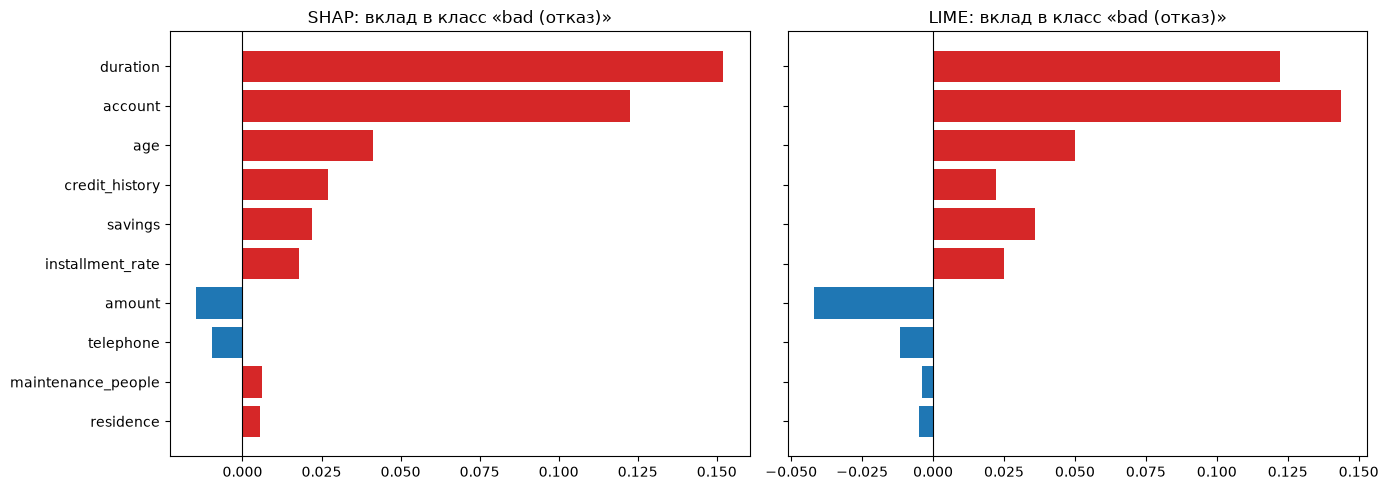

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
top = cmp.head(10).iloc[::-1]
for ax, col in zip(axes, ['SHAP', 'LIME']):
    ax.barh(top.index, top[col], color=np.where(top[col] > 0, 'tab:red', 'tab:blue'))
    ax.axvline(0, color='black', lw=0.8); ax.set_title(f'{col}: вклад в класс «{class_names[prediction]}»')
plt.tight_layout(); plt.show()

| Характеристика | SHAP | LIME |
|---|---|---|
| Тип объяснения | глобальное и локальное | преимущественно локальное |
| Основа метода | значения Шепли (теория игр) | локальная линейная аппроксимация |
| Модель-независимость | возможна (KernelExplainer), для деревьев — точный TreeExplainer | да, нужна только функция `predict_proba` |
| Объяснение одного прогноза | да (waterfall) | да (as_list, график) |
| Анализ модели в целом | да (bar, beeswarm) | ограниченно |
| Аддитивность (сумма вкладов = прогноз) | да, проверено выше | нет |
| Устойчивость | детерминированный результат | зависит от случайных возмущений |
| Форма вклада | вклад конкретного значения признака | вклад условия-интервала (`savings <= 0.00`) |

In [22]:
best = top_features.head(5)
print('Пять наиболее значимых признаков по SHAP (глобально):')
for _, r in best.iterrows():
    print(f"  {r['Feature']:16s} среднее |SHAP| = {r['MeanAbsSHAP']:.4f}   ({r['влияние']})")
print(f"\nКачество модели на test: accuracy = {accuracy_score(y_test, y_pred):.3f}, ROC-AUC = {roc_auc_score(y_test, proba_test):.3f}")
print(f"Объяснённый клиент: прогноз «{class_names[prediction]}» с вероятностью {probability[prediction]:.2f}")
print('Главные причины по SHAP:', ', '.join(shap_local.head(3).index))
print('Главные причины по LIME:', ', '.join(cmp.sort_values('ранг LIME').head(3).index))

Пять наиболее значимых признаков по SHAP (глобально):
  account          среднее |SHAP| = 0.0590   (больше → надёжнее)
  duration         среднее |SHAP| = 0.0399   (больше → рискованнее)
  amount           среднее |SHAP| = 0.0321   (больше → рискованнее)
  credit_history   среднее |SHAP| = 0.0305   (больше → надёжнее)
  age              среднее |SHAP| = 0.0237   (больше → надёжнее)

Качество модели на test: accuracy = 0.795, ROC-AUC = 0.823
Объяснённый клиент: прогноз «bad (отказ)» с вероятностью 0.68
Главные причины по SHAP: duration, account, age
Главные причины по LIME: account, duration, age
